In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv(r"C:\Users\SHREYA C RAMANI\Downloads\archive (3)\StudentsPerformance.csv")
print("First 5 rows of the dataset:")
print(df.head())
print("Last 5 rows of the dataset:")
print(df.tail())
print("\nDataset shape:")
print(df.shape)
data=df["math score"].dropna()
print("\nNumber of math score values:",len(data))
Q1=data.quantile(0.25)
Q3=data.quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
print("\nIQR Method")
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower limit:",lower_limit)
print("Upper limit:",upper_limit)
iqr_outliers=df[
    (df["math score"]<lower_limit)|
    (df["math score"]>upper_limit)
    ]
print("Number of IQR ouliers:",len(iqr_outliers))
mean=data.mean()
std=data.std()
df["Z_score"]=(df["math score"]-mean)/std
z_outliers=df[abs(df["Z_score"])>3]
print("\nZ-Score Method")
print("Mean:",mean)
print("Standard Deviation:",std)
print("Number of Z-score outliers:",len(z_outliers))


First 5 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
Last 5 rows of the dataset:
     gender race/ethnicity parental level of education         lunch  \
995  female        group E    

In [7]:
print("\nOutliers")
if len(iqr_outliers)>0:
    print(iqr_outliers[["math score"]])
else:
    print("No IQR outliers found.")
    
print("\n Z-score outliers")
if (len(z_outliers)>0):
     print(z_outliers[["math score","Z_score"]])
else:
     print("No z-score outliers found")
    


Outliers
     math score
17           18
59            0
145          22
338          24
466          26
787          19
842          23
980           8

 Z-score outliers
     math score   Z_score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [8]:
df["math_score_treated"]=df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit
)
print("Treatment method : capping using IQR limits")

Treatment method : capping using IQR limits


In [9]:
print("\nbefore treament")
print(df["math score"].describe())
print("\nafter treatment")
print(df["math_score_treated"].describe())
comparison = df[
    ["math score" , "math_score_treated"]
]
print(comparison.head(20))


before treament
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

after treatment
count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math_score_treated, dtype: float64
    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15  

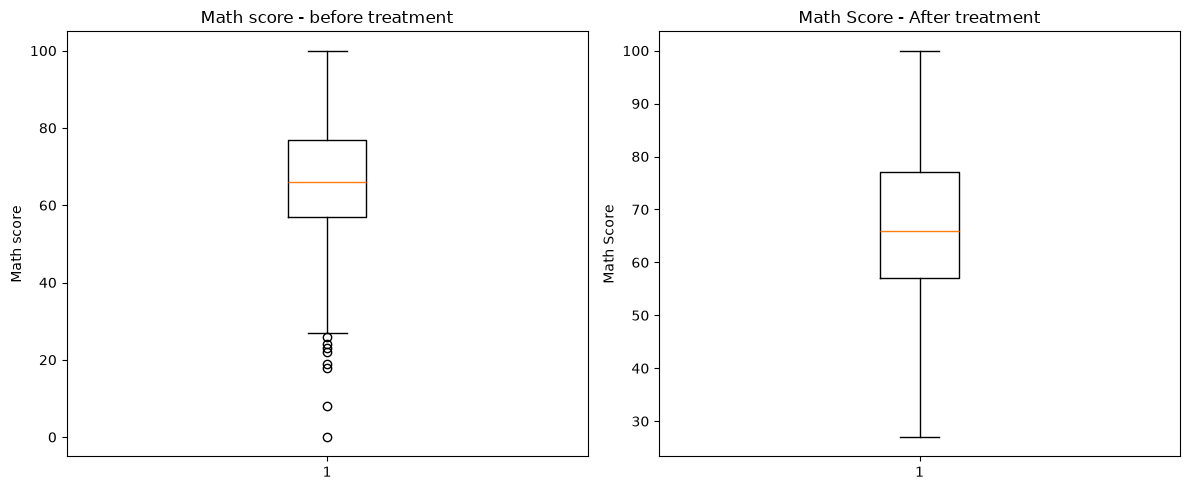

In [10]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math score - before treatment")
plt.ylabel("Math score")
plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After treatment")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()

